# Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp
from scipy.signal import hilbert

# Global parameters
mu = 1.0
omega1, omega2 = 1.0, 1.2
K_sibka, K_mocna = 0.1, 0.8
y0 = [0.8, 0.0, -0.2, 0.0]
t_end, t_prehod = 400.0, 100.0

rtol, atol = 1e-8, 1e-10

# Funkcije

In [2]:
# Simbolno: amplituda limitnega cikla VdP pri majhnem mu (energijska bilanca cez eno periodo)
t_s, A_s = sp.symbols("t A", positive=True)
x_h = A_s * sp.cos(t_s)
# dE/dt = mu (1 - x^2) xdot^2 ; povprecje cez periodo mora biti 0
bilanca = sp.integrate((1 - x_h**2) * sp.diff(x_h, t_s)**2, (t_s, 0, 2 * sp.pi))
A_lc = sp.solve(sp.Eq(bilanca, 0), A_s)

In [3]:
def vdp2(t, y, mu, w1, w2, K):
    x1, v1, x2, v2 = y
    return [v1, mu * (1 - x1**2) * v1 - w1**2 * x1 + K * (x2 - x1),
            v2, mu * (1 - x2**2) * v2 - w2**2 * x2 + K * (x1 - x2)]

def simuliraj(K, mu=mu, w2=omega2, t_end=t_end, n=40001, rtol=rtol):
    t = np.linspace(0, t_end, n)
    return solve_ivp(vdp2, (0, t_end), y0, args=(mu, omega1, w2, K), t_eval=t, rtol=rtol, atol=atol)

def faza(x):
    return np.unwrap(np.angle(hilbert(x - x.mean())))

def frekvenca(t, x):
    # povprecna krozna frekvenca iz pozitivnih prehodov skozi 0 (linearna interpolacija)
    i = np.where((x[:-1] < 0) & (x[1:] >= 0))[0]
    tc = t[i] - x[i] * (t[i + 1] - t[i]) / (x[i + 1] - x[i])
    return 2 * np.pi * (len(tc) - 1) / (tc[-1] - tc[0])

# Testno območje

In [4]:
# Pripravljalna naloga 1: A = 2
display(sp.Eq(sp.Symbol(r"\oint (1 - x^2)\dot{x}^2 dt"), sp.simplify(bilanca)))
print("A_lc =", A_lc)
for m_ in [0.1, 1.0, 3.0]:
    s = solve_ivp(vdp2, (0, 200), [0.1, 0, 0, 0], args=(m_, 1.0, 1.0, 0.0), t_eval=np.linspace(150, 200, 5001), rtol=rtol)
    print(f"mu = {m_}: numericna amplituda = {s.y[0].max():.3f}")

Eq(\oint (1 - x^2)\dot{x}^2 dt, pi*A**2*(4 - A**2)/4)

A_lc = [2]
mu = 0.1: numericna amplituda = 2.000
mu = 1.0: numericna amplituda = 2.009
mu = 3.0: numericna amplituda = 2.023


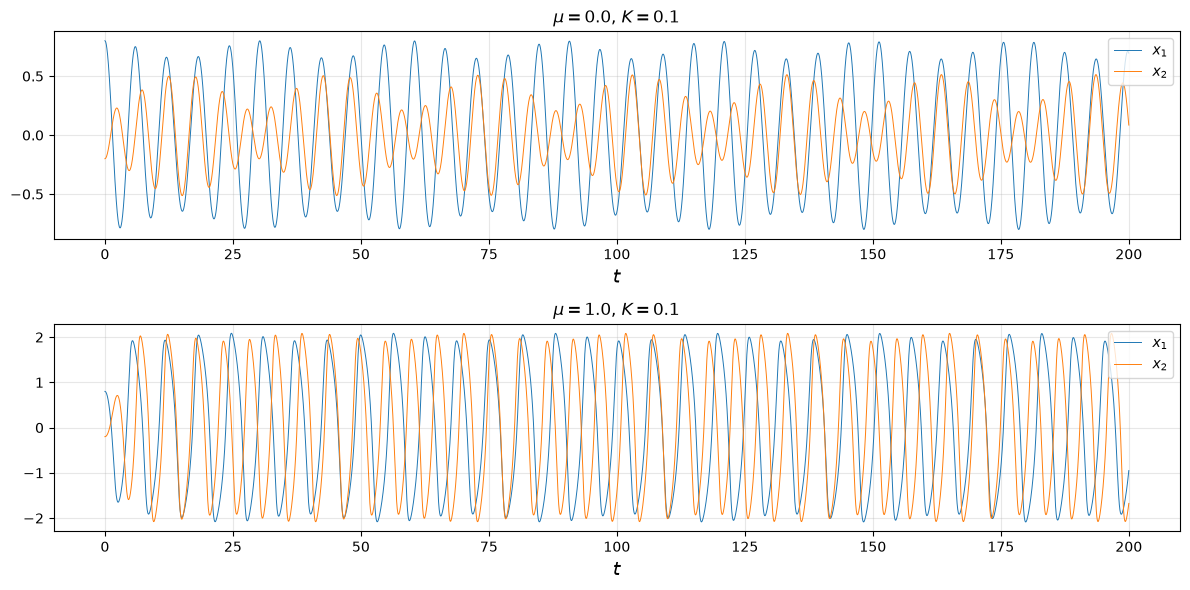

In [5]:
# Pripravljalna naloga 2: linearno utripanje (mu = 0) proti nelinearnemu (mu = 1)
fig = plt.figure(figsize=(12, 6))
for i, m_ in enumerate([0.0, 1.0]):
    s = simuliraj(K_sibka, mu=m_, t_end=200, n=20001)
    ax = fig.add_subplot(2, 1, i + 1)
    ax.plot(s.t, s.y[0], linewidth=0.7, label="$x_1$")
    ax.plot(s.t, s.y[2], linewidth=0.7, label="$x_2$")
    ax.set_title(rf"$\mu = {m_}$, $K = {K_sibka}$")
    ax.set_xlabel("$t$", fontsize=14)
    ax.legend(loc="upper right")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Naloga 1

K = 0.1: Omega_1 = 0.9911, Omega_2 = 1.1905, razmerje = 1.2012


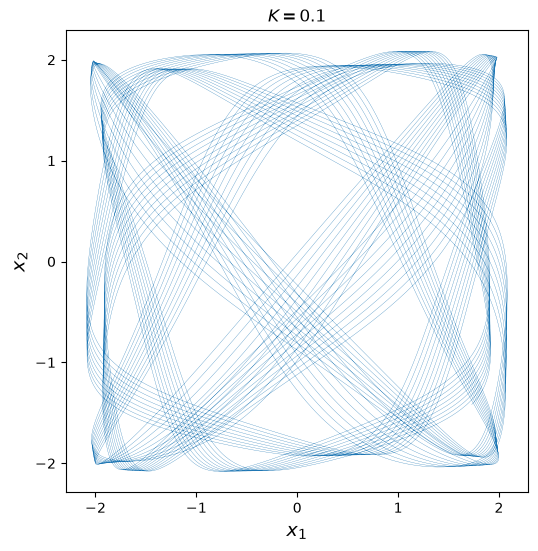

In [6]:
s1 = simuliraj(K_sibka)
m_ = s1.t > t_prehod
O1, O2 = frekvenca(s1.t[m_], s1.y[0, m_]), frekvenca(s1.t[m_], s1.y[2, m_])
print(f"K = {K_sibka}: Omega_1 = {O1:.4f}, Omega_2 = {O2:.4f}, razmerje = {O2 / O1:.4f}")

fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111)
ax.plot(s1.y[0, m_], s1.y[2, m_], linewidth=0.2)
ax.set_xlabel("$x_1$", fontsize=14)
ax.set_ylabel("$x_2$", fontsize=14)
ax.set_aspect("equal")
ax.set_title(rf"$K = {K_sibka}$")
plt.show()

# Naloga 2

K = 0.8: Omega_1 = 1.6284, Omega_2 = 1.6284, razmerje = 1.0000


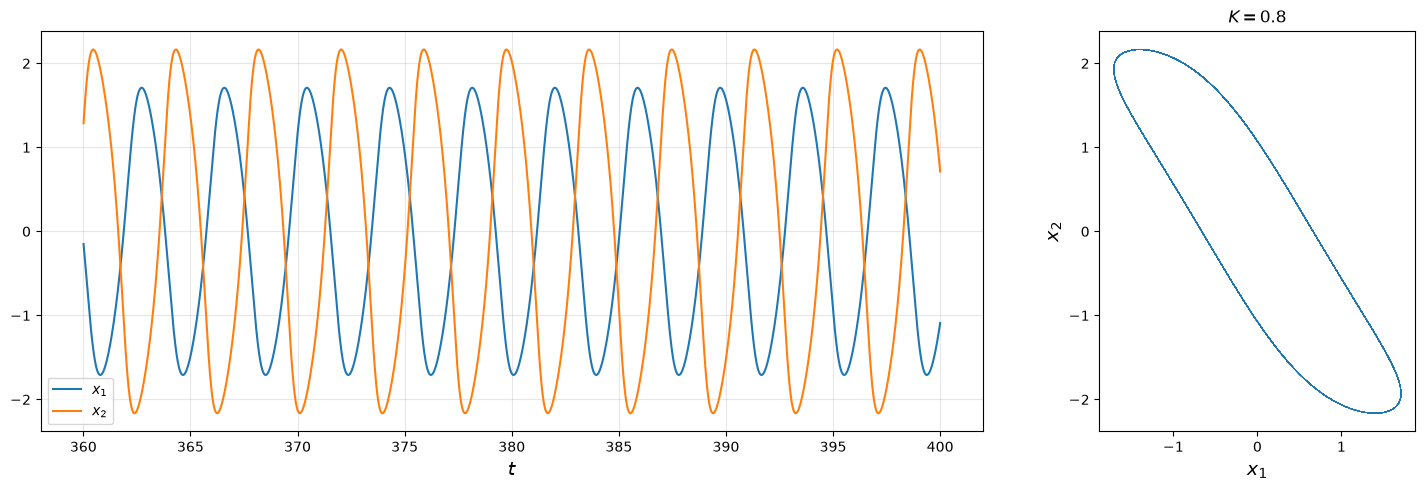

In [7]:
s2 = simuliraj(K_mocna)
O1, O2 = frekvenca(s2.t[m_], s2.y[0, m_]), frekvenca(s2.t[m_], s2.y[2, m_])
print(f"K = {K_mocna}: Omega_1 = {O1:.4f}, Omega_2 = {O2:.4f}, razmerje = {O2 / O1:.4f}")

fig = plt.figure(figsize=(15, 5))
ax = fig.add_subplot(1, 3, (1, 2))
m_k = s2.t > t_end - 40
ax.plot(s2.t[m_k], s2.y[0, m_k], label="$x_1$")
ax.plot(s2.t[m_k], s2.y[2, m_k], label="$x_2$")
ax.set_xlabel("$t$", fontsize=14)
ax.legend()
ax.grid(alpha=0.3)
ax = fig.add_subplot(1, 3, 3)
ax.plot(s2.y[0, m_], s2.y[2, m_], linewidth=0.5)
ax.set_xlabel("$x_1$", fontsize=14)
ax.set_ylabel("$x_2$", fontsize=14)
ax.set_aspect("equal")
ax.set_title(rf"$K = {K_mocna}$")
plt.tight_layout()
plt.show()

# Naloga 3

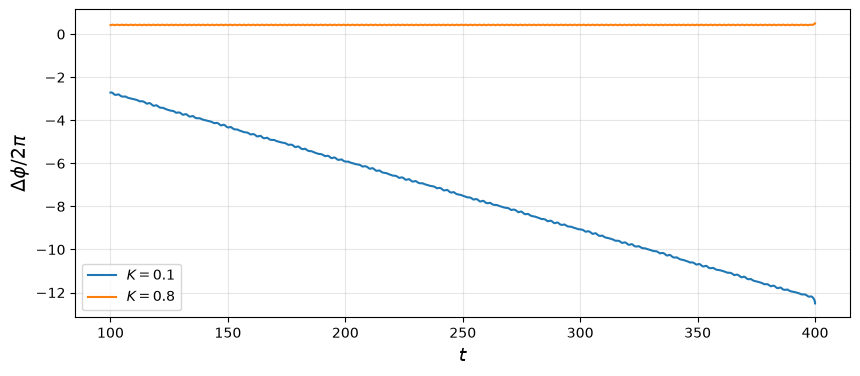

In [8]:
fig = plt.figure(figsize=(10, 4))
ax = fig.add_subplot(111)
for s, K in [(s1, K_sibka), (s2, K_mocna)]:
    dphi = faza(s.y[0]) - faza(s.y[2])
    ax.plot(s.t[m_], dphi[m_] / (2 * np.pi), label=rf"$K = {K}$")
ax.set_xlabel("$t$", fontsize=14)
ax.set_ylabel(r"$\Delta\phi / 2\pi$", fontsize=14)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

# Razmislek 1

In [9]:
# Kriticna sklopitev K_c za omega_2 = 1.2
K_os = np.linspace(0.45, 0.65, 21)
dO = []
for K in K_os:
    s = simuliraj(K, t_end=600, n=30001, rtol=1e-7)
    mm = s.t > 250
    dO.append(abs(frekvenca(s.t[mm], s.y[0, mm]) - frekvenca(s.t[mm], s.y[2, mm])))
dO = np.array(dO)
K_c = K_os[np.argmax(dO < 1e-3)]
print(f"omega_2 = {omega2}: K_c ~ {K_c:.2f}")

omega_2 = 1.2: K_c ~ 0.55


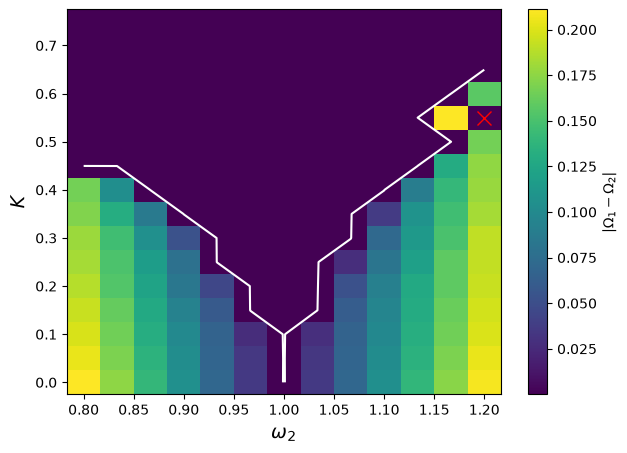

In [10]:
# Arnoldov jezik: |Omega_1 - Omega_2| v ravnini (omega_2, K)
w2_os = np.linspace(0.8, 1.2, 13)
K_os2 = np.linspace(0.0, 0.75, 16)
mapa = np.zeros((len(K_os2), len(w2_os)))
for i, K in enumerate(K_os2):
    for j, w2 in enumerate(w2_os):
        s = simuliraj(K, w2=w2, t_end=400, n=20001, rtol=1e-7)
        mm = s.t > 150
        mapa[i, j] = abs(frekvenca(s.t[mm], s.y[0, mm]) - frekvenca(s.t[mm], s.y[2, mm]))

fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(111)
pc = ax.pcolormesh(w2_os, K_os2, mapa, shading="nearest", cmap="viridis")
ax.contour(w2_os, K_os2, mapa, levels=[1e-3], colors="white")
fig.colorbar(pc, ax=ax, label=r"$|\Omega_1 - \Omega_2|$")
ax.plot(omega2, K_c, "x", color="red", markersize=10)
ax.set_xlabel(r"$\omega_2$", fontsize=14)
ax.set_ylabel("$K$", fontsize=14)
plt.show()